# Assignment # 03

## Real Estate Agency

### Task 1.1 Data Overview and Cleaning

The dataset was cleaned using a combination of basic data preparation techniques and checklist-based consistency checks.

- Missing values in the `Age` column were imputed using the median.  
- Rows with missing or zero values in the `Price` column were treated as invalid and removed.  
- Duplicate entries were identified and dropped.  
- Text-based columns such as `SaleStatus`, `Location`, and `Type` were stripped of whitespace, standardized in casing, and converted to the `category` data type for efficiency.  
- Numerical columns were checked for logical consistency:
  - Properties with negative `Age`, non-positive `Size`, or non-positive `Tenure` were removed.  
  - Annual property tax values were required to be strictly lower than the `Price`.  
  - Each property was required to have at least one room.  
  - Properties were allowed to have zero bathrooms, but negative values were filtered out.

In [1]:
# task1.1

# Importing pandas library
import pandas as pd

# Importing dataset
df = pd.read_csv("data/RealEstate_Data.csv")  # change path if needed

# Looking dataset info
df.info()

# Checking for duplicated rows
print("\nDuplicated rows:", df.duplicated().sum())

# Checking for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Filling missing Age values with median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Replacing 0s in Price with NaN
df["Price"] = df["Price"].replace(0, pd.NA)

# Droping rows where Price is still missing
df = df.dropna(subset=["Price"])

# Droping duplicated rows
df = df.drop_duplicates()

# Standardizing text columns and convert to category
df["SaleStatus"] = df["SaleStatus"].str.strip().str.capitalize().astype("category")
df["Location"] = df["Location"].str.strip().str.title().astype("category")
df["Type"] = df["Type"].str.strip().str.title().astype("category")

# 10. Removing logically inconsistent rows
df = df[df["Age"] >= 0]
df = df[df["Size"] > 0]
df = df[df["Tenure"] > 0]
df = df[df["AnnualPropertyTax"] < df["Price"]]
df = df[df["NumberOfRooms"] >= 1]
df = df[df["NumberOfBathrooms"] >= 0]

# Resetting index
df = df.reset_index(drop=True)

# Checking unrealistic prices
mean_price = df["Price"].mean()
median_price = df["Price"].median()
max_price = df["Price"].max()
min_price = df["Price"].min()

print("Price statistics:")
print(f"\nMean: {mean_price:.2f}")
print(f"\nMedian: {median_price:.2f}")
print(f"\nMin: {min_price}")
print(f"\nMax: {max_price}")

# Showing cleaned data
df.head()
df.info()

# Copying cleaned data
df_cleaned = df.copy()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5005 entries, 0 to 5004
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PropertyID         5005 non-null   int64  
 1   Age                4975 non-null   float64
 2   Location           5005 non-null   object 
 3   StartYear          5005 non-null   int64  
 4   Type               5005 non-null   object 
 5   NumberOfRooms      5005 non-null   int64  
 6   NumberOfBathrooms  5005 non-null   int64  
 7   Size               5005 non-null   int64  
 8   Price              4967 non-null   float64
 9   SaleStatus         5005 non-null   object 
 10  MonthlyHOAFees     5005 non-null   int64  
 11  AnnualPropertyTax  5005 non-null   int64  
 12  PerformanceRating  5005 non-null   int64  
 13  TotalDaysListed    5005 non-null   int64  
 14  Tenure             5005 non-null   int64  
dtypes: float64(2), int64(10), object(3)
memory usage: 586.7+ KB

Duplicated 

## Task 1.2: Measurement Scales of Attributes

Each attribute in the dataset was evaluated based on its nature and usage.  
Below is a classification of the measurement scales:

- **Nominal**: PropertyID, Location, Type, SaleStatus  
- **Ordinal**: PerformanceRating  
- **Ratio**: Age, StartYear, NumberOfRooms, NumberOfBathrooms, Size, Price, MonthlyHOAFees, AnnualPropertyTax, TotalDaysListed, Tenure

Attributes such as `Price`, `Size`, and `Tenure` are ratio-scaled because they have a true zero and meaningful numerical comparisons can be made.  
Categorical variables such as `Type` and `Location` are nominal because they have no inherent order.  
`PerformanceRating` is considered ordinal due to its ranked nature but without equal intervals between values.


### Task 2.1: Age Distribution Visualization

A **histogram** was used to visualize the distribution of `Age`.  
According to the lecture, histograms are suitable for displaying the frequency distribution of a single continuous variable, showing the shape, spread, and skewness of the data.  
The figure-level function `displot` in Seaborn was applied, as it offers flexible bin control (`bins` or `binwidth`) and easy customization of axis labels and titles.

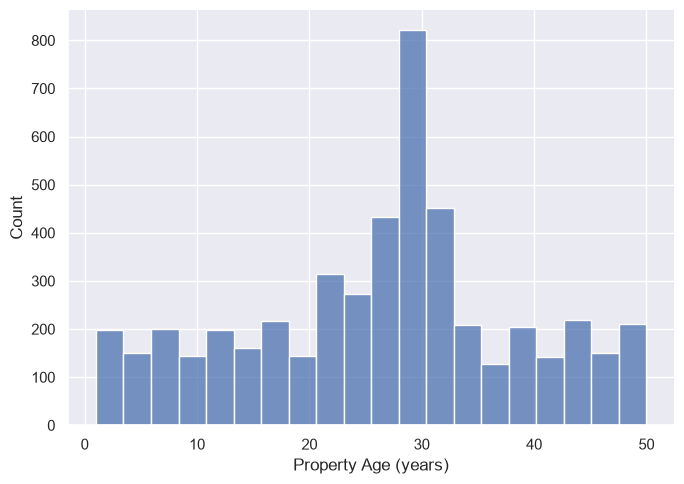

In [2]:
# task2.1

import seaborn as sns

sns.set_theme()

g = sns.displot(
    data=df_cleaned,
    x="Age",
    kind="hist",
    bins=20,
    height=5,
    aspect=1.4
)

g.set_axis_labels("Property Age (years)", "Count")
g.set_titles("Distribution of Property Age")


### Task 2.2: Age distribution by Location

A **box plot** was selected to compare the distribution of a continuous variable (`Age`) across categories (`Location`).  
According to the lecture, *categorical distribution plots* such as **box plots** are designed to show the distribution (quartiles, spread, skewness, outliers) and **facilitate comparisons between groups**.



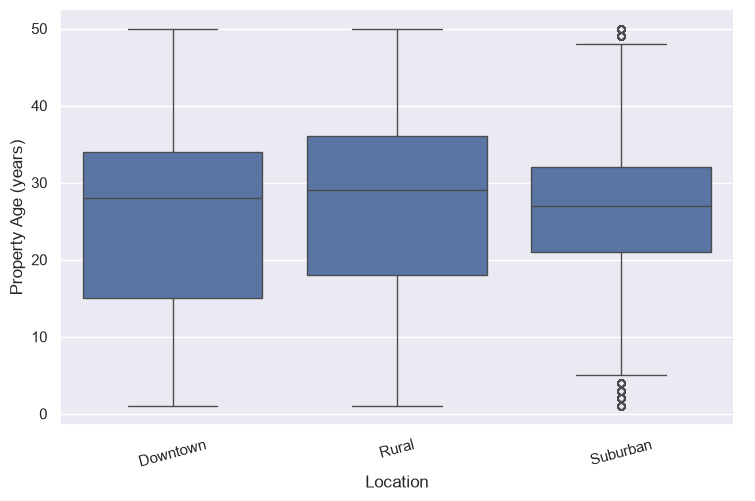

In [3]:
# task2.2

import seaborn as sns

# Use Seaborn's default theme
sns.set_theme()

# Figure-level categorical distribution plot (box)
g = sns.catplot(
    data=df_cleaned,
    x="Location",
    y="Age",
    kind="box",
    height=5,
    aspect=1.5
)

# Title and axis labels via FacetGrid methods (lecture shows this pattern)
g.set_titles("Property Age by Location")
g.set_axis_labels("Location", "Property Age (years)")
g.set_xticklabels(rotation=15)


### Task 2.3: Probability Density Function of Property Prices

A **kernel density estimation (KDE)** plot was used to visualize the probability density function of `Price`.  
According to the lecture, KDE is effective for detecting **skewness**, **multimodality**, and **outliers** in continuous data by providing a smooth estimation of the underlying distribution.  
The plot displays `Price` on the x-axis and the estimated probability density on the y-axis, allowing quick visual inspection of the overall shape and spread of the data.


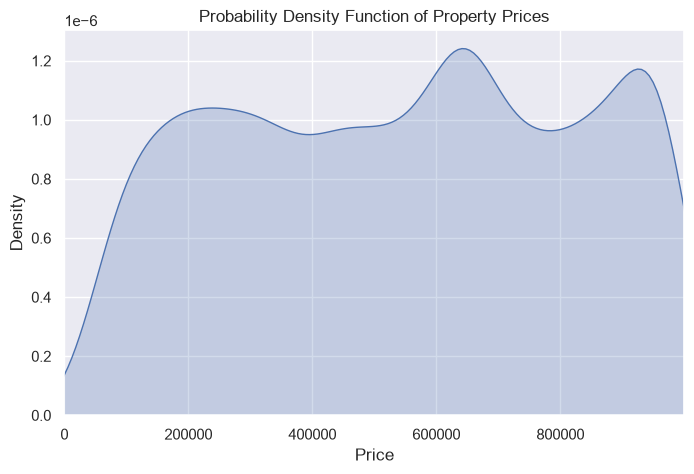

In [4]:
# task2.3

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme()

plt.figure(figsize=(8, 5))
g = sns.kdeplot(
    data=df_cleaned,
    x="Price",
    fill=True,
    bw_adjust=1
)

g.set(xlim=(0, 999999))
plt.title("Probability Density Function of Property Prices")
plt.xlabel("Price")
plt.ylabel("Density")
plt.show()


### Task 2.4: Probability Density of Price by Performance Rating

A **kernel density estimation (KDE)** plot was created to visualize the distribution of `Price` for each level of the `PerformanceRating` variable.  
The `hue` parameter was used to draw separate density curves for each category, enabling direct visual comparison.  
This method allows detection of **differences in skewness**, **spread**, and **modal patterns** between the performance levels, as recommended in the lecture for comparing continuous distributions across categorical groups.


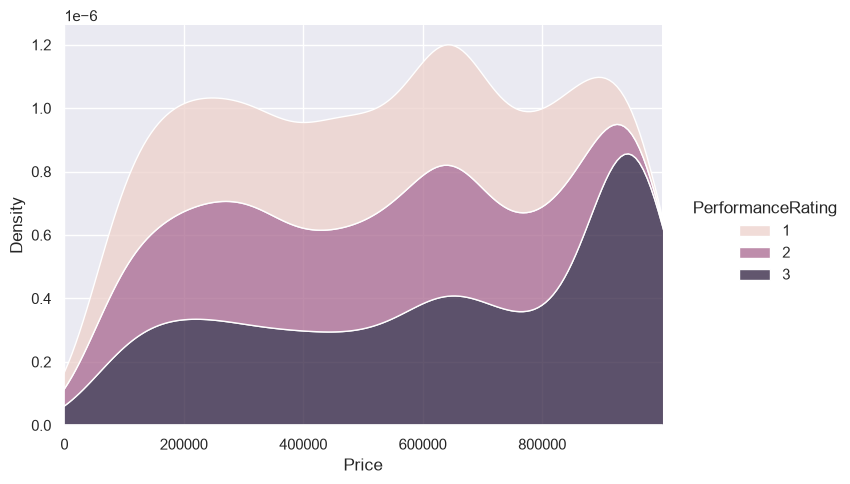

In [5]:
# task2.4

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme()

g = sns.displot(
    data=df_cleaned,
    x="Price",
    hue="PerformanceRating",
    kind="kde",
    fill=True,
    height=5,
    aspect=1.4,
    multiple = "stack"
)

g.set(xlim=(0, 999999))
g.set_axis_labels("Price", "Density")
g.set_titles("Price Distribution by Performance Rating")
plt.show()


### Task 2.5: Empirical Cumulative Distribution of Monthly HOA Fees

An **ECDF plot** was created to visualize the cumulative proportion of properties by their `MonthlyHOAFees`.  
From the plot and calculations:
- **16.57%** of properties have HOA fees less than $300.  
- To belong to the top **15%** of HOA fees, a property must charge at least **$707**.

The ECDF allows direct interpretation of proportions and thresholds without binning, making it a precise tool for identifying fee distribution cut-offs.


Percent below $300: 16.57%
Top 15% threshold: $707.00


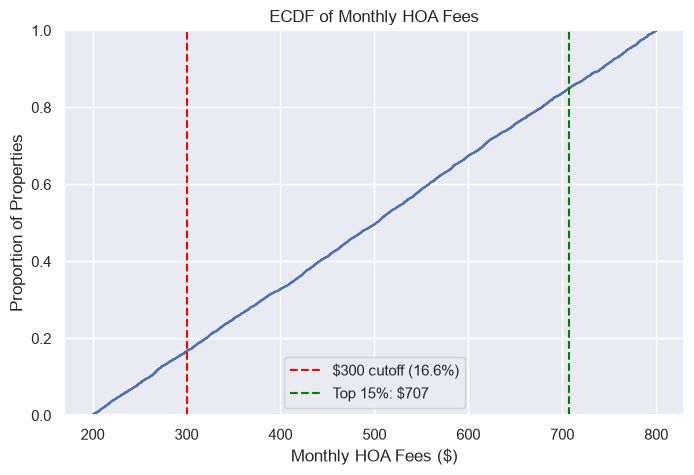

In [6]:
# task2.5

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme()

# Calculate statistics
pct_below_300 = (df_cleaned["MonthlyHOAFees"] < 300).mean() * 100
fee_top15_threshold = df_cleaned["MonthlyHOAFees"].quantile(0.85)

print(f"Percent below $300: {pct_below_300:.2f}%")
print(f"Top 15% threshold: ${fee_top15_threshold:.2f}")

# Plot ECDF
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df_cleaned, x="MonthlyHOAFees")
plt.axvline(300, color="red", linestyle="--", label=f"$300 cutoff ({pct_below_300:.1f}%)")
plt.axvline(fee_top15_threshold, color="green", linestyle="--", label=f"Top 15%: ${fee_top15_threshold:.0f}")
plt.xlabel("Monthly HOA Fees ($)")
plt.ylabel("Proportion of Properties")
plt.title("ECDF of Monthly HOA Fees")
plt.legend()
plt.show()


### Task 2.6: Joint Distribution of Price and Age

A **joint plot** was used to visualize the relationship between `Price` and `Age`.  
The scatter plot within the joint plot allows examination of the spread and correlation between the two variables, while the marginal histograms show the univariate distributions of each.  
This visualization helps detect potential patterns, such as whether older properties tend to be priced lower or higher, and to identify clusters or outliers.


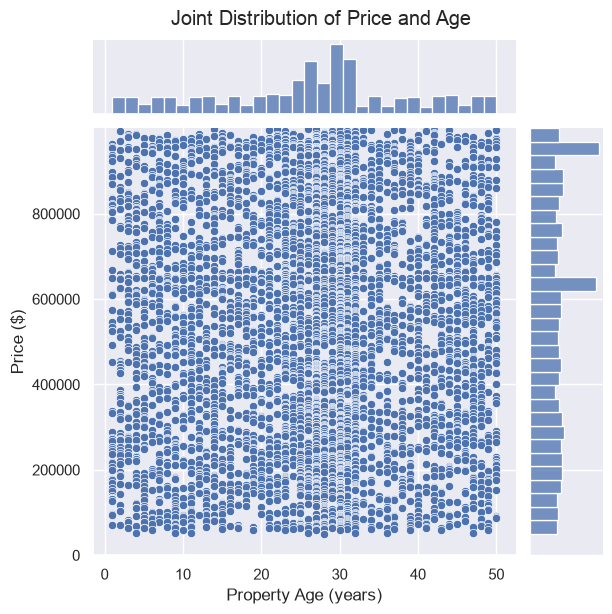

In [7]:
# task2.6

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme()

g = sns.jointplot(
    data=df_cleaned,
    x="Age",
    y="Price",
    kind="scatter",
    height=6,
    marginal_kws=dict(bins=30, fill=True)
)

g.ax_joint.set_ylim(0, 999999)
g.set_axis_labels("Property Age (years)", "Price ($)")
g.fig.suptitle("Joint Distribution of Price and Age", y=1.02)

plt.show()


### Task 2.7: Price vs Total Days Listed by Property Type

A **scatter plot** was created using `relplot` to visualize the relationship between `TotalDaysListed` and `Price`, separated by property `Type`.  
Using facets for each property type allows for easier comparison of trends and outlier patterns between categories, without overlapping points from different groups.


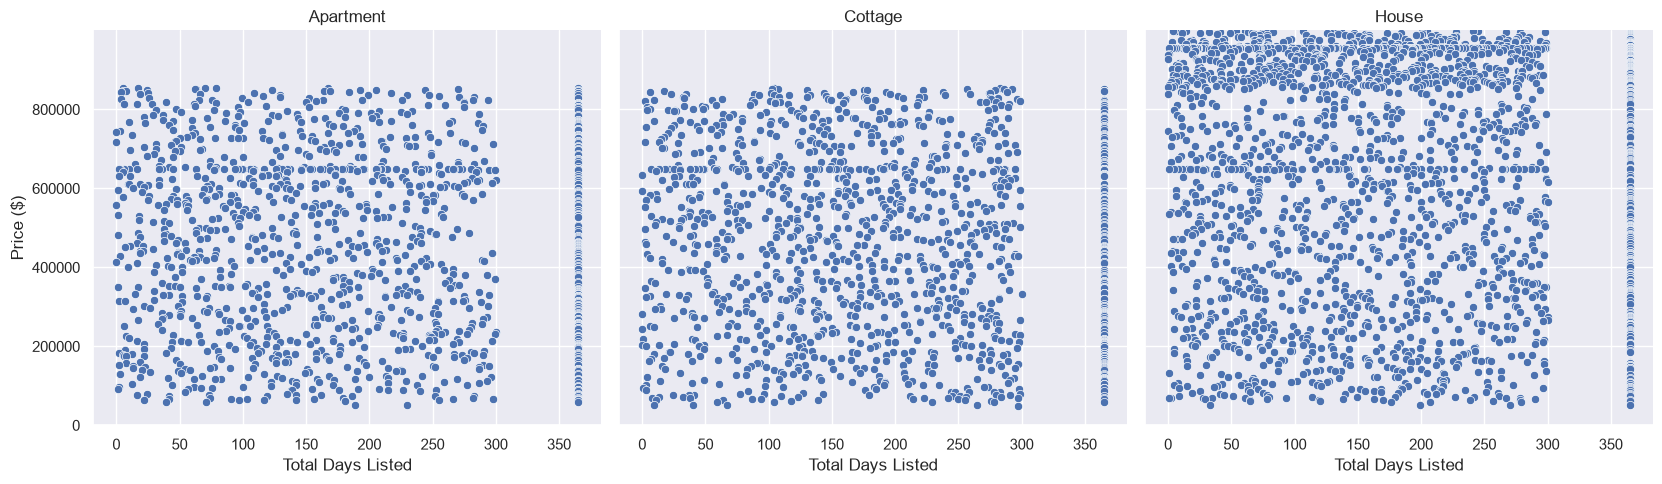

In [8]:
# task2.7

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme()

g = sns.relplot(
    data=df_cleaned,
    x="TotalDaysListed",
    y="Price",
    col="Type",        
    kind="scatter",
    height=5,
    aspect=1.1
)

g.set(ylim=(0, 999999))
g.set_axis_labels("Total Days Listed", "Price ($)")
g.set_titles("{col_name}")
plt.show()


### Task 2.8: Annual Property Tax by Start Year

A **categorical plot** (`sns.catplot`) with `kind="box"` was used to visualize the distribution of `AnnualPropertyTax` across different `StartYear` values.  
This approach effectively shows medians, interquartile ranges, and potential outliers for each year while preserving categorical ordering.


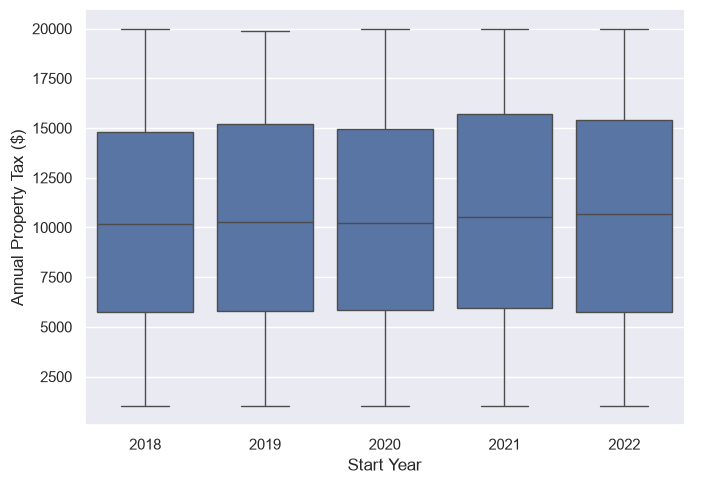

In [9]:
# task2.8

import seaborn as sns

sns.set_theme()

g = sns.catplot(
    data=df_cleaned,
    x="StartYear",
    y="AnnualPropertyTax",
    kind="box",
    height=5,
    aspect=1.4
)

g.set_axis_labels("Start Year", "Annual Property Tax ($)")
g.set_titles("Annual Property Tax Distribution by Start Year")


### Task 2.9: Price Distribution by Type and Location

A grouped **box plot** was created using `sns.catplot` to compare the distribution of `Price` across different combinations of `Type` and `Location`.  
This visualization makes it possible to examine median prices, spread, and outliers while clearly separating the effects of both categorical variables.


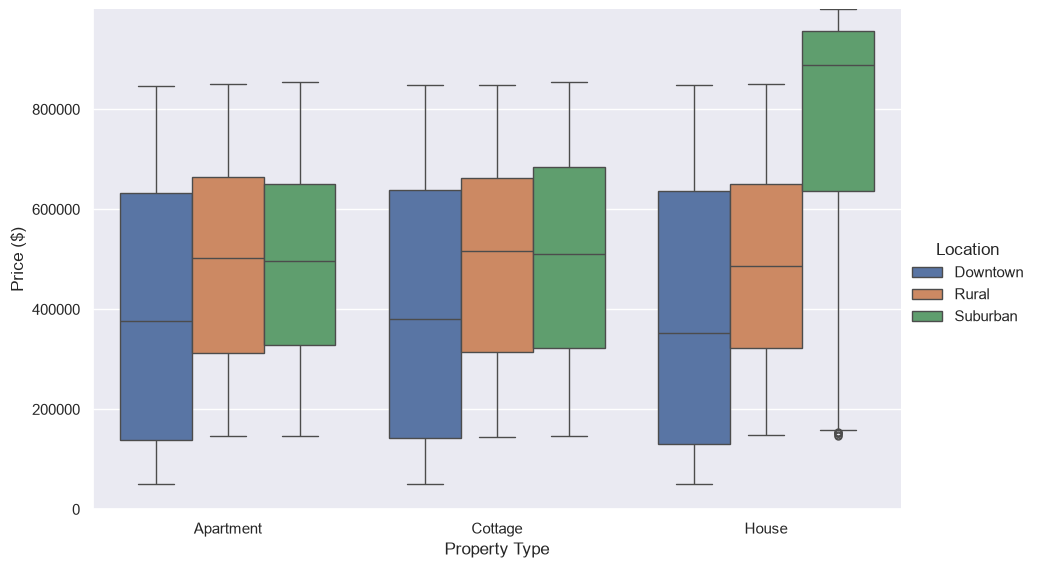

In [10]:
# task2.9

import seaborn as sns

sns.set_theme()

g = sns.catplot(
    data=df_cleaned,
    x="Type",
    y="Price",
    hue="Location",
    kind="box",
    height=6,
    aspect=1.5
)

g.set(ylim=(0, 999999))
g.set_axis_labels("Property Type", "Price ($)")
g.set_titles("Price Distribution by Property Type and Location")


### Task 2.10: Price Distribution and Outliers by Property Type

A **box plot** was used to visualize the distribution of `Price` across different `Type` categories.  
Box plots display the median, interquartile range (IQR), and explicitly mark outliers as individual points.  
This allows for quick identification of which property type has the largest number and spread of outliers.


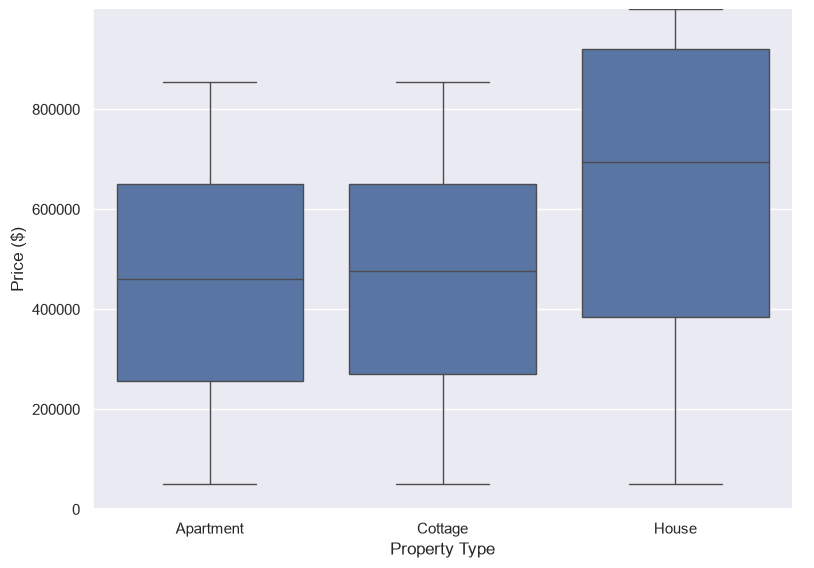

In [11]:
# task2.10 

import seaborn as sns

sns.set_theme()

g = sns.catplot(
    data=df_cleaned,
    x="Type",
    y="Price",
    kind="box",
    height=6,
    aspect=1.3
)

g.set(ylim=(0, 999999))
g.set_axis_labels("Property Type", "Price ($)")
g.set_titles("Price Distribution and Outliers by Property Type")


### Task 2.11 – Distribution of Price by Property Type and Outlier Detection

A boxplot was chosen to visualize the distribution of `property prices` across `property types`.  
This visualization clearly marks outliers as points beyond the whiskers, making it easier to identify which property type has the highest number of extreme values.  
The y-axis is restricted to the realistic price range to keep the plot readable.


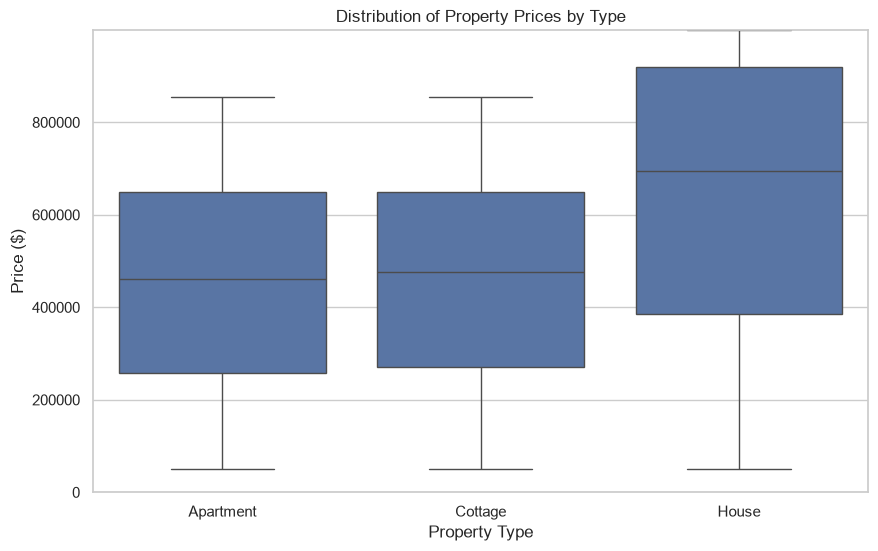

In [12]:
# task2.11

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_cleaned,
    x="Type",
    y="Price"
)

plt.ylim(0, 999000)
plt.title("Distribution of Property Prices by Type")
plt.xlabel("Property Type")
plt.ylabel("Price ($)")
plt.show()


### Task 2.12 - Rooms, Bathrooms vs Price

A simplified relational scatter plot was created to show how the `number of rooms and bathrooms` in a property relate to its `price`.  

- **X-axis:** Number of bathrooms  
- **Y-axis:** Number of rooms  
- **Hue (color):** Property price  

This format is visually clean and directly communicates the relationship between layout and pricing without overcomplicating the chart.

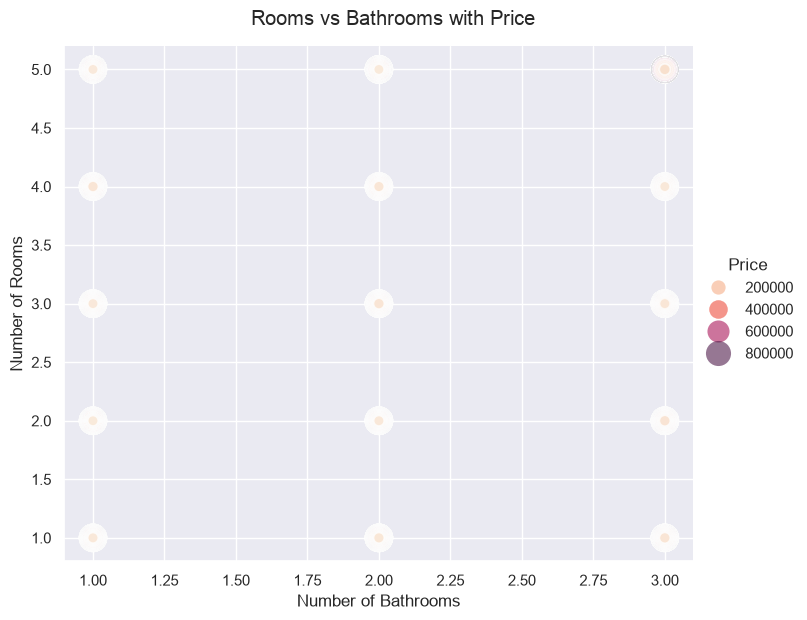

In [13]:
# task2.12

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme()

g = sns.relplot(
    data=df_cleaned,
    x="NumberOfBathrooms",
    y="NumberOfRooms",
    hue="Price",
    size="Price",
    palette="rocket_r",
    kind="scatter",
    sizes=(50, 400),
    alpha=0.6,
    height=6,
    aspect=1.2
)

g.set_axis_labels("Number of Bathrooms", "Number of Rooms")
g.figure.suptitle("Rooms vs Bathrooms with Price", y=1.03)
plt.show()


### Task 2.13 – Average Price by Property Type across Locations

A faceted bar plot was used to compare the average property prices across different property types and locations.  
Each subplot represents one location and shows how average price varies by property type within that location.

This visualization clearly reveals whether the impact of property type on price is consistent across locations, or if it varies — suggesting a possible interaction between the two categorical variables.

The separate panels (facets) allow for easier comparison and highlight differences that may be masked in a combined plot.


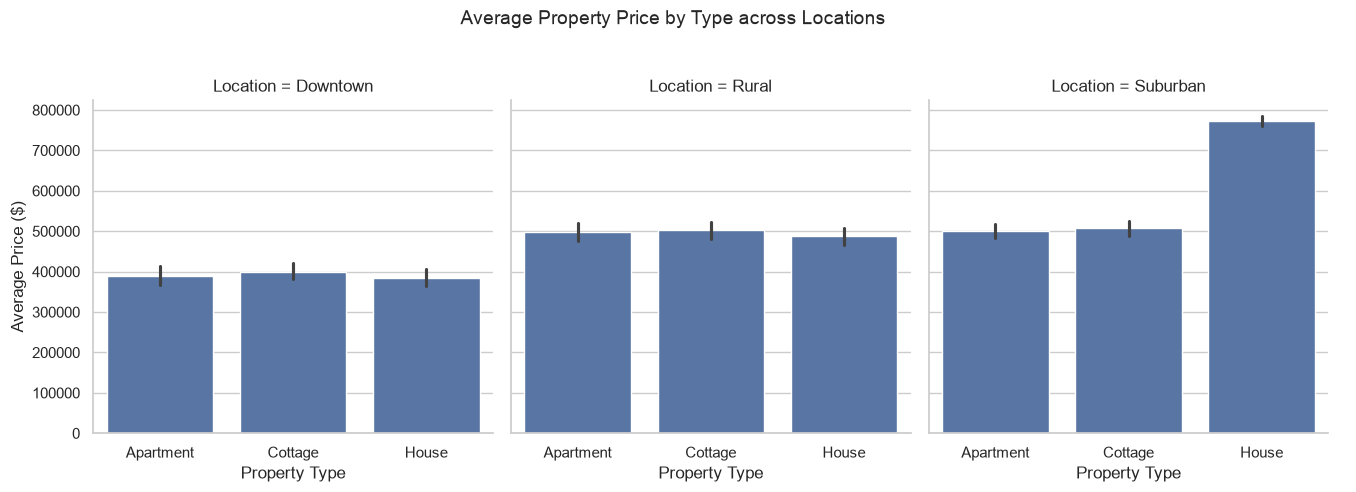

In [14]:
# task2.13

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

g = sns.catplot(
    data=df_cleaned,
    x="Type",
    y="Price",
    col="Location",
    kind="bar",
    estimator="mean",
    height=5,
    aspect=0.9
)

g.fig.subplots_adjust(top=0.8)
g.fig.suptitle("Average Property Price by Type across Locations", fontsize=14)
g.set_axis_labels("Property Type", "Average Price ($)")
